In [ ]:
import pandas as pd
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import seaborn as sns
# import os
# import tarfile
# import matplotlib
# import re

import igraph as ig
import leidenalg as la

In [2]:
# Initializing the graph from data

nodes = pd.read_csv(
    "../data/hep-th-slacdates.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["id", "date"], 
    dtype=str  
)


edges = pd.read_csv(
    "../data/hep-th-citations.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["From", "To"], 
    dtype=str
)

# 3. Get unique node IDs from both columns of the edge list
node_ids = pd.unique(edges[["From", "To"]].values.ravel())

# 4. Get actual nodes listed in edge list
nodes_used = nodes[nodes["id"].isin(node_ids)].copy()

# 5. Make a directed graph smoothly
g_directed = nx.DiGraph()

# Convert the filtered nodes dataframe into a dictionary of attributes and load them
node_attributes = nodes_used.set_index("id").to_dict("index")
g_directed.add_nodes_from(node_attributes.keys())
nx.set_node_attributes(g_directed, node_attributes)

# Add the edges directly from the edge dataframe tuples
g_directed.add_edges_from(edges.itertuples(index=False, name=None))

# Print properties to verify success
print("--- GRAPH INITIALIZATION SUCCESSFUL ---")
print(f"Nodes in graph: {g_directed.number_of_nodes()}")
print(f"Edges in graph: {g_directed.number_of_edges()}")

--- GRAPH INITIALIZATION SUCCESSFUL ---
Nodes in graph: 27770
Edges in graph: 352807


In [3]:
# Assigning node attribute for easy extraction by year

nodes_used["year"] = pd.to_numeric(nodes_used["date"].str.slice(0,4), errors='coerce')
nx.set_node_attributes(g_directed, nodes_used.set_index("id")["year"].to_dict(), "year")

In [ ]:
# # Transferring from networkx graph to iGraph graph since leiden clustering works with iGraph graphs.

# nodes_1993 = [id for id, year in nx.get_node_attributes(g_directed, "year").items() if year <= 1993]
# g_directed_1993 = g_directed.subgraph(nodes_1993)

# # Explicit node -> integer index mapping (igraph vertices are always 0..n-1 internally)
# nodes_1993_list = list(g_directed_1993.nodes())
# node_index = {node: idx for idx, node in enumerate(nodes_1993_list)}

# # Translate edges through the same mapping, preserving (source, target) order = preserving direction
# edges_idx = [(node_index[u], node_index[v]) for u, v in g_directed_1993.edges()]

# g_ig_1993 = ig.Graph(n=len(nodes_1993_list), edges=edges_idx, directed=True)
# g_ig_1993.vs["name"] = nodes_1993_list   # keep original paper IDs as a vertex attribute for lookup later

In [ ]:
# partition_1993 = la.find_partition(
#     g_ig_1993,
#     la.RBConfigurationVertexPartition,
#     seed=35
# )

In [ ]:
# community_map_1993 = {}
# for community_id, community in enumerate(partition_1993):
#     for vertex_idx in community:
#         node_id = g_ig_1993.vs[vertex_idx]["name"]
#         community_map_1993[node_id] = community_id

# print(community_map_1993)

{'9206080': 0, '9301020': 0, '9204090': 0, '9212139': 0, '9307185': 0, '9209008': 0, '9207105': 0, '9209122': 0, '9309138': 0, '9310101': 0, '9309046': 0, '9206107': 0, '9307079': 0, '9310046': 0, '9305040': 0, '9306041': 0, '9212002': 0, '9210088': 0, '9301082': 0, '9212136': 0, '9305003': 0, '9305117': 0, '9210038': 0, '9302127': 0, '9204028': 0, '9306097': 0, '9211082': 0, '9206070': 0, '9312036': 0, '9207095': 0, '9206020': 0, '9210017': 0, '9302080': 0, '9205114': 0, '9206071': 0, '9302024': 0, '9210101': 0, '9302009': 0, '9205030': 0, '9204026': 0, '9207046': 0, '9212044': 0, '9302144': 0, '9311148': 0, '9206056': 0, '9303002': 0, '9211079': 0, '9302040': 0, '9203060': 0, '9306069': 0, '9301058': 0, '9312127': 0, '9309075': 0, '9212120': 0, '9204042': 0, '9205028': 0, '9307140': 0, '9303140': 0, '9208056': 0, '9312021': 0, '9312017': 0, '9206087': 0, '9209064': 0, '9307157': 0, '9302022': 0, '9304027': 0, '9201074': 0, '9209118': 0, '9308020': 0, '9306141': 0, '9204002': 0, '9206

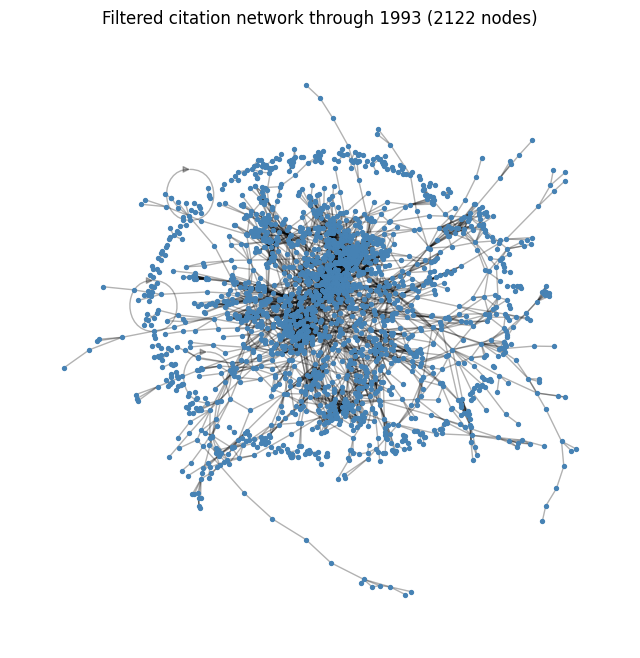

In [ ]:
# def plot_filtered_network(G, year, seed=35, node_size=8):
#     plt.figure(figsize=(8, 8))
#     pos = nx.spring_layout(G, seed=seed)
#     nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color="steelblue")
#     nx.draw_networkx_edges(G, pos, alpha=0.3, arrows=False)
#     plt.title(f"Filtered citation network through {year} ({G.number_of_nodes()} nodes)")
#     plt.axis("off")
#     plt.show()

# plot_filtered_network(slice_graphs[1993], 1993)


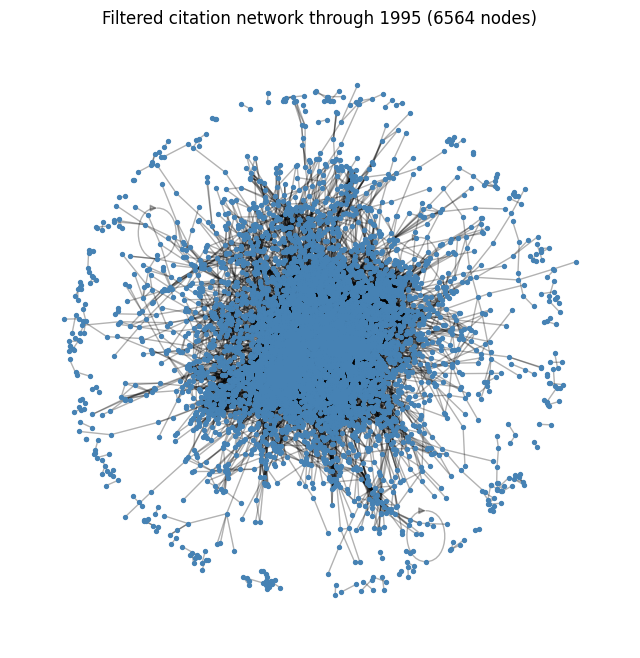

In [ ]:
# plot_filtered_network(slice_graphs[1995], 1995)

During my previous runs, there were a lot of islands with 2-3 nodes. Hence filtering these isolated islands.

In [4]:
def filter_graph_by_component_size(nx_graph, min_component_size):
    components = nx.weakly_connected_components(nx_graph)  # weakly connected: direction irrelevant for reachability here
    keep_nodes = set()
    for comp in components:
        if len(comp) >= min_component_size:
            keep_nodes.update(comp)
    return nx_graph.subgraph(keep_nodes).copy()

In [5]:
MIN_COMPONENT_SIZE = 10 

time_slices = [1993, 1995, 1997, 1999, 2001, 2003]
slice_graphs = {}

for slice_year in time_slices:
    nodes_in_range = [n for n, y in nx.get_node_attributes(g_directed, "year").items() if y <= slice_year]
    sub = g_directed.subgraph(nodes_in_range)

    connected_nodes = [n for n in sub.nodes() if sub.degree(n) > 0]
    degree_filtered = sub.subgraph(connected_nodes).copy()

    filtered_sub = filter_graph_by_component_size(degree_filtered, MIN_COMPONENT_SIZE)

    slice_graphs[slice_year] = filtered_sub
    print(f"{slice_year}: {sub.number_of_nodes()} -> {degree_filtered.number_of_nodes()} (degree filter) "
          f"-> {filtered_sub.number_of_nodes()} (component-size filter, min={MIN_COMPONENT_SIZE})")

1993: 2801 -> 2122 (degree filter) -> 1805 (component-size filter, min=10)
1995: 7085 -> 6564 (degree filter) -> 6229 (component-size filter, min=10)
1997: 12128 -> 11824 (degree filter) -> 11420 (component-size filter, min=10)
1999: 17475 -> 17275 (degree filter) -> 16880 (component-size filter, min=10)
2001: 23586 -> 23498 (degree filter) -> 23112 (component-size filter, min=10)
2003: 27770 -> 27770 (degree filter) -> 27410 (component-size filter, min=10)


In [6]:
# Creating the dictionary with partitions for further processing

# Without sorted earlier, notebooks hashing was giving nodes in a different order 
# Thus to tackle this, while the graph is creating the nodes are sorted at the start 
# Thus preventing different outputs everytime the notebook is run.
# And hence reproducibility is maintained for the project.

def nx_to_igraph(nx_graph):
    node_list = sorted(nx_graph.nodes()) # prevent PYTHONHASHSEED to randomize the order of nodes, thereby impacting the persistent communities differences in every run.
    node_index = {node: idx for idx, node in enumerate(node_list)}
    edges_idx = [(node_index[u], node_index[v]) for u, v in sorted(nx_graph.edges())]
    g_ig = ig.Graph(n=len(node_list), edges=edges_idx, directed=True)
    g_ig.vs["name"] = node_list
    return g_ig

def run_leiden(nx_graph, seed = 35):
    g_ig = nx_to_igraph(nx_graph)
    partition = la.find_partition(g_ig, la.RBConfigurationVertexPartition, seed = seed)
    return [{g_ig.vs[v]['name'] for v in community} for community in partition]

slice_partitions = {}
for slice_year in time_slices:
    slice_partitions[slice_year] = run_leiden(slice_graphs[slice_year])
    sizes = [len(c) for c in slice_partitions[slice_year]]
    print(f"{slice_year}: {len(slice_partitions[slice_year])} communities, largest = {max(sizes)}")

1993: 32 communities, largest = 151
1995: 38 communities, largest = 571
1997: 29 communities, largest = 1005
1999: 28 communities, largest = 1369
2001: 30 communities, largest = 2447
2003: 32 communities, largest = 2817


Old tracking code

In [ ]:
# from collections import defaultdict

# THRESHOLD = 0.5
# MIN_SIZE = 10
# MAJOR_FACTOR = 0.15

# global_label_counter = 0
# slice_global_map = {}
# lineage_log = []
# split_log = {}
# merge_log = {}

# base_slice = time_slices[0]
# slice_global_map[base_slice] = {}
# for local_id in range(len(slice_partitions[base_slice])):
#     slice_global_map[base_slice][local_id] = global_label_counter
#     lineage_log.append((None, None, base_slice, local_id, None, "birth"))
#     global_label_counter += 1

# for prev_slice, curr_slice in zip(time_slices[:-1], time_slices[1:]):
#     prev_sets = slice_partitions[prev_slice]   # already sets from run_leiden — no re-casting needed
#     curr_sets = slice_partitions[curr_slice]
#     prev_global = slice_global_map[prev_slice]

#     curr_global = {}
#     parent_overlaps_by_curr = defaultdict(list)

#     for curr_id, curr_set in enumerate(curr_sets):
#         B = len(curr_set)
#         best_sim = 0.0
#         best_prev_id = None

#         for prev_id, prev_set in enumerate(prev_sets):
#             overlap = len(prev_set & curr_set)
#             if overlap == 0:
#                 continue
#             parent_overlaps_by_curr[curr_id].append((prev_id, overlap))
#             A = len(prev_set)
#             sim = overlap / min(A, B)
#             if sim > best_sim:
#                 best_sim = sim
#                 best_prev_id = prev_id

#         if best_prev_id is not None and best_sim >= THRESHOLD:
#             A_best = len(prev_sets[best_prev_id])
#             curr_global[curr_id] = prev_global[best_prev_id]

#             if best_sim == 1.0:
#                 status = "same"
#             elif A_best < MIN_SIZE and B < MIN_SIZE:
#                 status = "minor"
#             elif B > A_best:
#                 status = "growth"
#             elif B < A_best:
#                 status = "shrink"
#             else:
#                 status = "continue"

#             lineage_log.append((prev_slice, best_prev_id, curr_slice, curr_id, best_sim, status))
#         else:
#             curr_global[curr_id] = global_label_counter
#             lineage_log.append((prev_slice, best_prev_id, curr_slice, curr_id, best_sim, "birth"))
#             global_label_counter += 1

#     slice_global_map[curr_slice] = curr_global

#     # split sweep
#     for prev_id, prev_set in enumerate(prev_sets):
#         A = len(prev_set)
#         if A == 0:
#             continue
#         overlaps = [(cid, len(prev_set & cs)) for cid, cs in enumerate(curr_sets)]
#         overlaps = [(cid, ov) for cid, ov in overlaps if ov > 0]
#         major_children = [(cid, ov) for cid, ov in overlaps if ov / A >= MAJOR_FACTOR]
#         if len(major_children) >= 2:
#             split_log[(prev_slice, prev_id)] = {
#                 "children": major_children,
#                 "mass_covered": sum(ov for _, ov in major_children) / A
#             }

#     # promote confirmed split children from 'birth' to 'split'
#     for i, row in enumerate(lineage_log):
#         r_prev_slice, r_prev_id, r_curr_slice, r_curr_id, r_sim, r_status = row
#         if r_status != "birth" or r_curr_slice != curr_slice or r_prev_slice != prev_slice:
#             continue
#         info = split_log.get((prev_slice, r_prev_id))
#         if info and any(cid == r_curr_id for cid, _ in info["children"]):
#             lineage_log[i] = (r_prev_slice, r_prev_id, r_curr_slice, r_curr_id, r_sim, "split")

#     # merge sweep
#     for curr_id, overlaps in parent_overlaps_by_curr.items():
#         B = len(curr_sets[curr_id])
#         major_parents = [(pid, ov) for pid, ov in overlaps if ov / len(prev_sets[pid]) >= MAJOR_FACTOR]
#         if len(major_parents) >= 2:
#             merge_log[(curr_slice, curr_id)] = {
#                 "parents": major_parents,
#                 "mass_covered": sum(ov for _, ov in major_parents) / B
#             }

Previous persistent communities (communities existing in atleast 4 timelines) size distribution using Jaccard

size 2: 57 communities 

size 3: 19 communities 

size 4: 4 communities 

size 5: 5 communities 

size 6: 4 communities 

size 8: 2 communities 

size 1394: 1 communities

In [ ]:
# Actual size distribution of communities throughout the timeline.

comms = {}
for slice_year in time_slices:
    sizes = sorted((len(c) for c in slice_partitions[slice_year]), reverse=True)
    print(f"{slice_year}: top 10 sizes = {sizes[:10]}, total communities = {len(sizes)}")

1993: top 10 sizes = [161, 157, 142, 136, 119, 106, 91, 78, 64, 63], total communities = 33
1995: top 10 sizes = [653, 501, 449, 397, 374, 346, 324, 283, 260, 248], total communities = 37
1997: top 10 sizes = [1197, 1081, 995, 964, 937, 773, 719, 644, 566, 482], total communities = 39
1999: top 10 sizes = [1369, 1216, 1179, 1167, 1156, 1118, 1091, 1061, 941, 918], total communities = 28
2001: top 10 sizes = [2447, 1982, 1827, 1412, 1409, 1379, 1309, 1272, 1243, 1208], total communities = 30
2003: top 10 sizes = [2817, 2198, 2035, 1953, 1831, 1707, 1647, 1636, 1605, 1472], total communities = 32


In [10]:
THRESHOLD = 0.5

for prev_slice, curr_slice in zip(time_slices[:-1], time_slices[1:]):
    prev_sets = slice_partitions[prev_slice]
    curr_sets = slice_partitions[curr_slice]

    large_curr = [(cid, cs) for cid, cs in enumerate(curr_sets) if len(cs) >= 100]
    best_sims = []
    for curr_id, curr_set in large_curr:
        # Using Jaccard similarity 
        best_sim = max(
            (len(prev_set & curr_set) / (len(prev_set) + len(curr_set) - len(prev_set & curr_set))
             for prev_set in prev_sets),
            default=0.0
        )
        best_sims.append(best_sim)

    below_threshold = sum(1 for s in best_sims if s < THRESHOLD)
    print(f"{prev_slice} -> {curr_slice}: {len(large_curr)} large (≥100) communities, "
          f"{below_threshold} fall below THRESHOLD={THRESHOLD}, "
          f"best_sim range = [{min(best_sims):.3f}, {max(best_sims):.3f}]")

1993 -> 1995: 19 large (≥100) communities, 19 fall below THRESHOLD=0.5, best_sim range = [0.000, 0.254]
1995 -> 1997: 19 large (≥100) communities, 16 fall below THRESHOLD=0.5, best_sim range = [0.041, 0.563]
1997 -> 1999: 19 large (≥100) communities, 15 fall below THRESHOLD=0.5, best_sim range = [0.023, 0.713]
1999 -> 2001: 22 large (≥100) communities, 18 fall below THRESHOLD=0.5, best_sim range = [0.087, 0.651]
2001 -> 2003: 22 large (≥100) communities, 12 fall below THRESHOLD=0.5, best_sim range = [0.102, 0.827]


As visible, Jaccard similarity gives a bad score because there is an explosive growth in the sizes of the communities which were getting filtered out through Jaccard threshold. Consider an example of this community:

<code>58: {'timeline': [(1997, 33, 5, 'birth'),
   (1999, 11, 803, 'growth'),
   (2001, 15, 851, 'growth'),
   (2003, 0, 2817, 'growth')]}
</code>

Consider A --> community 33 (1997) of size 5
which becomes B --> community 11 (1999) if size 803 

IntersectionOf(A, B) = 5 (nodes which were from previous year 1997)
UnionOf(A,B) = A + B - IntersectionOf(A, B)
   = 5 + 803 - 5 = 803

Thus Jaccard = 5/803 = 0.0062266500622665

In the end Jaccard turns in J = A / B.
And in any community which grows more than twice in size will not reach the threshold of 0.5.

Thus, modified the tracking using overlap / min(A, B) which signifies whether the smallest community was completely swallowed by the new communnity or not which in-turn helped in tracking the previously smaller communities. 

## Current tracking code


In [7]:
from collections import defaultdict

THRESHOLD = 0.5
MIN_SIZE = 10
MAJOR_FACTOR = 0.15

global_label_counter = 0
slice_global_map = {}
lineage_log = []
split_log = {}
merge_log = {}

base_slice = time_slices[0]
slice_global_map[base_slice] = {}
for local_id in range(len(slice_partitions[base_slice])):
    slice_global_map[base_slice][local_id] = global_label_counter
    lineage_log.append((None, None, base_slice, local_id, None, "birth"))
    global_label_counter += 1

for prev_slice, curr_slice in zip(time_slices[:-1], time_slices[1:]):
    prev_sets = slice_partitions[prev_slice]
    curr_sets = slice_partitions[curr_slice]
    prev_global = slice_global_map[prev_slice]

    parent_overlaps_by_curr = defaultdict(list)
    best_match_by_curr = {}   # curr_id -> (best_prev_id, best_sim)

    # Pass 1: find every curr_id's best match
    for curr_id, curr_set in enumerate(curr_sets):
        B = len(curr_set)
        best_sim = 0.0
        best_prev_id = None

        for prev_id, prev_set in enumerate(prev_sets):
            overlap = len(prev_set & curr_set)
            if overlap == 0:
                continue
            parent_overlaps_by_curr[curr_id].append((prev_id, overlap))
            A = len(prev_set)
            sim = overlap / min(A, B)
            if sim > best_sim:
                best_sim = sim
                best_prev_id = prev_id

        best_match_by_curr[curr_id] = (best_prev_id, best_sim)

    # Pass 2: group by which prev community each curr_id claimed
    claims_by_prev = defaultdict(list)
    for curr_id, (best_prev_id, best_sim) in best_match_by_curr.items():
        if best_prev_id is not None and best_sim >= THRESHOLD:
            claims_by_prev[best_prev_id].append(curr_id)

    # only the largest claimant per parent keeps the parent's identity — everyone else is a split child
    winner_by_prev = {
        prev_id: max(curr_ids, key=lambda cid: len(curr_sets[cid]))
        for prev_id, curr_ids in claims_by_prev.items()
    }

    curr_global = {}
    for curr_id, curr_set in enumerate(curr_sets):
        B = len(curr_set)
        best_prev_id, best_sim = best_match_by_curr[curr_id]
        cleared_threshold = best_prev_id is not None and best_sim >= THRESHOLD
        is_winner = cleared_threshold and winner_by_prev[best_prev_id] == curr_id

        if is_winner:
            A_best = len(prev_sets[best_prev_id])
            curr_global[curr_id] = prev_global[best_prev_id]

            if A_best == B and best_sim == 1.0:
                status = "same"                      
            elif A_best < MIN_SIZE and B < MIN_SIZE:
                status = "minor"
            elif B > A_best:
                status = "growth"
            elif B < A_best:
                status = "shrink"
            else:
                status = "continue"

            lineage_log.append((prev_slice, best_prev_id, curr_slice, curr_id, best_sim, status))

        elif cleared_threshold:
            # matched a parent above threshold, but lost the identity to a bigger sibling — a split fragment
            curr_global[curr_id] = global_label_counter
            lineage_log.append((prev_slice, best_prev_id, curr_slice, curr_id, best_sim, "split"))
            global_label_counter += 1

        else:
            curr_global[curr_id] = global_label_counter
            lineage_log.append((prev_slice, best_prev_id, curr_slice, curr_id, best_sim, "birth"))
            global_label_counter += 1

    slice_global_map[curr_slice] = curr_global

    # split sweep (mass-fraction based)
    for prev_id, prev_set in enumerate(prev_sets):
        A = len(prev_set)
        if A == 0:
            continue
        overlaps = [(cid, len(prev_set & cs)) for cid, cs in enumerate(curr_sets)]
        overlaps = [(cid, ov) for cid, ov in overlaps if ov > 0]
        major_children = [(cid, ov) for cid, ov in overlaps if ov / A >= MAJOR_FACTOR]
        if len(major_children) >= 2:
            split_log[(prev_slice, prev_id)] = {
                "children": major_children,
                "mass_covered": sum(ov for _, ov in major_children) / A
            }

    # promote any remaining sub-threshold split fragments that the sweep catches but the main loop missed
    for i, row in enumerate(lineage_log):
        r_prev_slice, r_prev_id, r_curr_slice, r_curr_id, r_sim, r_status = row
        if r_status != "birth" or r_curr_slice != curr_slice or r_prev_slice != prev_slice:
            continue
        info = split_log.get((prev_slice, r_prev_id))
        if info and any(cid == r_curr_id for cid, _ in info["children"]):
            lineage_log[i] = (r_prev_slice, r_prev_id, r_curr_slice, r_curr_id, r_sim, "split")

    # merge sweep
    for curr_id, overlaps in parent_overlaps_by_curr.items():
        B = len(curr_sets[curr_id])
        major_parents = [(pid, ov) for pid, ov in overlaps if ov / len(prev_sets[pid]) >= MAJOR_FACTOR]
        if len(major_parents) >= 2:
            merge_log[(curr_slice, curr_id)] = {
                "parents": major_parents,
                "mass_covered": sum(ov for _, ov in major_parents) / B
            }

In [ ]:
# split_log

{(1993, 1): {'children': [(0, 42), (4, 33), (17, 52)],
  'mass_covered': 0.8943661971830986},
 (1993, 3): {'children': [(0, 65), (1, 32)],
  'mass_covered': 0.8584070796460177},
 (1993, 8): {'children': [(4, 21), (6, 48)],
  'mass_covered': 0.8117647058823529},
 (1993, 9): {'children': [(1, 16), (5, 40)],
  'mass_covered': 0.7272727272727273},
 (1993, 11): {'children': [(2, 38), (13, 15)],
  'mass_covered': 0.7571428571428571},
 (1993, 13): {'children': [(2, 24), (14, 31)],
  'mass_covered': 0.9166666666666666},
 (1993, 14): {'children': [(8, 24), (10, 10), (11, 16)],
  'mass_covered': 0.8771929824561403},
 (1993, 18): {'children': [(7, 22), (20, 20)], 'mass_covered': 1.0},
 (1993, 26): {'children': [(3, 3), (28, 7)],
  'mass_covered': 0.8333333333333334},
 (1995, 0): {'children': [(7, 233), (8, 177)],
  'mass_covered': 0.7180385288966725},
 (1995, 2): {'children': [(3, 223), (6, 172)],
  'mass_covered': 0.8012170385395537},
 (1995, 6): {'children': [(3, 180), (6, 112)],
  'mass_covere

In [ ]:
# merge_log

{(1995, 0): {'parents': [(1, 42), (3, 65)],
  'mass_covered': 0.18739054290718038},
 (1995, 1): {'parents': [(0, 140), (3, 32), (9, 16), (12, 31), (29, 5)],
  'mass_covered': 0.3929824561403509},
 (1995, 2): {'parents': [(10, 67), (11, 38), (13, 24), (20, 34)],
  'mass_covered': 0.3306288032454361},
 (1995, 3): {'parents': [(2, 106), (26, 3)],
  'mass_covered': 0.2718204488778055},
 (1995, 4): {'parents': [(1, 33), (8, 21), (15, 46)],
  'mass_covered': 0.27548209366391185},
 (1995, 5): {'parents': [(9, 40), (19, 37)],
  'mass_covered': 0.21388888888888888},
 (1995, 6): {'parents': [(6, 69), (8, 48)],
  'mass_covered': 0.3391304347826087},
 (1995, 7): {'parents': [(7, 63), (18, 22)],
  'mass_covered': 0.25757575757575757},
 (1995, 8): {'parents': [(4, 70), (14, 24)],
  'mass_covered': 0.32752613240418116},
 (1995, 9): {'parents': [(5, 90), (22, 14)],
  'mass_covered': 0.4094488188976378},
 (1995, 10): {'parents': [(14, 10), (23, 13)],
  'mass_covered': 0.09787234042553192},
 (1995, 11):

In [ ]:
# Analyzing the communities which have lasted in at least 4 timelines.

community_lineage = defaultdict(lambda: {"timeline": []})

for local_id in range(len(slice_partitions[base_slice])):
    global_label = slice_global_map[base_slice][local_id]
    size = len(slice_partitions[base_slice][local_id])
    community_lineage[global_label]["timeline"].append((base_slice, local_id, size, "birth"))

for row in lineage_log:
    prev_slice, prev_id, curr_slice, curr_id, sim, status = row
    if curr_slice == base_slice:
        continue
    global_label = slice_global_map[curr_slice][curr_id]
    size = len(slice_partitions[curr_slice][curr_id])
    community_lineage[global_label]["timeline"].append((curr_slice, curr_id, size, status))

PERSISTENCE_THRESHOLD = 4

persistent_communities = {
    label: info for label, info in community_lineage.items()
    if len({t[0] for t in info["timeline"]}) >= PERSISTENCE_THRESHOLD 
}

print(f"{len(persistent_communities)} of {len(community_lineage)} total communities "
      f"persisted for at least {PERSISTENCE_THRESHOLD} of {len(time_slices)} timestamps")

17 of 82 total communities persisted for at least 4 of 6 timestamps


In [ ]:
# persistent_communities

{2: {'timeline': [(1993, 2, 125, 'birth'),
   (1995, 3, 401, 'growth'),
   (1997, 9, 601, 'growth'),
   (1999, 17, 444, 'shrink'),
   (2001, 19, 204, 'shrink'),
   (2003, 15, 741, 'growth')]},
 4: {'timeline': [(1993, 4, 101, 'birth'),
   (1995, 8, 287, 'growth'),
   (1997, 10, 521, 'growth'),
   (1999, 23, 9, 'shrink'),
   (2001, 4, 1409, 'growth'),
   (2003, 6, 1647, 'growth')]},
 16: {'timeline': [(1993, 16, 52, 'birth'),
   (1995, 16, 170, 'growth'),
   (1997, 1, 867, 'growth'),
   (1999, 1, 1216, 'growth'),
   (2001, 3, 1412, 'growth'),
   (2003, 2, 2035, 'growth')]},
 17: {'timeline': [(1993, 17, 50, 'birth'),
   (1995, 15, 176, 'growth'),
   (1997, 16, 300, 'growth'),
   (1999, 0, 1369, 'growth')]},
 25: {'timeline': [(1993, 25, 13, 'birth'),
   (1995, 29, 14, 'growth'),
   (1997, 12, 493, 'growth'),
   (1999, 4, 1156, 'growth')]},
 27: {'timeline': [(1993, 27, 11, 'birth'),
   (1995, 25, 26, 'growth'),
   (1997, 19, 174, 'growth'),
   (1999, 6, 1091, 'growth')]},
 29: {'timelin

In [10]:
slice_partitions[1997][28]

{'9311094', '9412148', '9604180', '9701111', '9804036'}

In [ ]:

# len(slice_partitions[2003][9])


1472

# Abstract analysis

In [ ]:
# Combining all the extracted paper information (parquet files) into a single file for analysis.

import pandas as pd
from pathlib import Path

DATA_DIR = Path("./abstract structured data")
years_needed = range(1992, 2004)  # include 1992 in case any paper_id in your graph traces back that far

paper_dfs = []
for year in years_needed:
    path = DATA_DIR / f"papers{year}.parquet"
    if path.exists():
        df = pd.read_parquet(path, columns=["paper_id", "year", "title", "subject", "embeddings", "scibert_data"])
        paper_dfs.append(df)
    else:
        print(f"Missing file: {path}")

papers_all = pd.concat(paper_dfs, ignore_index=True)
print(f"Loaded {len(papers_all)} papers from {len(paper_dfs)} files")

Loaded 29555 papers from 12 files


In [101]:
papers_all.head()

,paper_id,year,title,subject,embeddings,scibert_data
0,9201001,1992,Combinatorics of the Modular Group II: the Kon...,High Energy Physics - Theory; Quantum Algebra,"[combinatorics, modular, group, kontsevich, in...",[Combinatorics of the Modular Group II: the Ko...
1,9201002,1992,Inomogeneous Quantum Groups as Symmetries of P...,,"[inomogeneous, quantum, group, symmetry, phono...",[Inomogeneous Quantum Groups as Symmetries of ...
2,9201003,1992,"Intersection Theory, Integrable Hierarchies an...",,"[intersection, theory, integrable, hierarchy, ...","[Intersection Theory, Integrable Hierarchies a..."
3,9201004,1992,The Heterotic Green-Schwarz Superstring on an ...,,"[heterotic, green, schwarz, superstring, super...",[The Heterotic Green-Schwarz Superstring on an...
4,9201005,1992,Ward Identities in Two-Dimensional String Theory,,"[ward, identity, two, dimensional, string, the...",[Ward Identities in Two-Dimensional String The...


In [ ]:
# Checking how many papers have a subject line

# coverage = papers_all["subject"].notna().mean()
# print(f"{coverage:.1%} of papers have a non-null subject tag")
# if coverage > 0:
#     print(papers_all["subject"].value_counts().head(20))

100.0% of papers have a non-null subject tag
subject
                                                                       27012
High Energy Physics - Theory; Quantum Algebra                            676
High Energy Physics - Theory; Mathematical Physics                       404
High Energy Physics - Theory; Exactly Solvable and Integrable            285
High Energy Physics - Theory; Algebraic Geometry                         181
High Energy Physics - Theory; Differential Geometry                      133
High Energy Physics - Theory; Statistical Mechanics                       95
High Energy Physics - Theory; Mathematical Physics; Exactly               82
High Energy Physics - Theory; Mathematical Physics; Quantum Algebra       46
High Energy Physics - Theory; Quantum Algebra; Exactly Solvable and       41
High Energy Physics - Theory; Mesoscopic Systems and Quantum Hall         40
High Energy Physics - Theory; Functional Analysis                         36
High Energy Physics - T

In [12]:
paper_id_to_tokens = papers_all.set_index("paper_id")["embeddings"].to_dict()   # for TF-IDF labeling

TF-IDF code was not providing any useful terms to determine the community headings

In [ ]:
# def build_community_docs(persistent_communities, slice_partitions, paper_id_to_tokens):
#     community_docs = {}
#     for label, info in persistent_communities.items():
#         paper_ids = set()
#         for slice_year, local_id, size, status in info["timeline"]:
#             paper_ids.update(slice_partitions[slice_year][local_id])

#         tokens = []
#         for pid in paper_ids:
#             t = paper_id_to_tokens.get(pid)
#             if t is not None:
#                 tokens.extend(t)
#         community_docs[label] = tokens
#     return community_docs

# community_docs = build_community_docs(persistent_communities, slice_partitions, paper_id_to_tokens)

In [ ]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from collections import Counter

# # Step 1: fit IDF on the full paper-level corpus 
# paper_texts = papers_all.set_index("paper_id")["embeddings"].apply(lambda toks: " ".join(toks))

# corpus_vectorizer = TfidfVectorizer(
#     tokenizer=lambda x: x.split(),
#     preprocessor=lambda x: x,
#     lowercase=False,
#     min_df=5,      # drop extremely rare tokens (likely typos / OCR noise), meaningful now with 29,500 docs
#     max_df=0.5     # exclude words in >50% of ALL papers — now a statistically meaningful cutoff, not a coin-flip
# )
# corpus_vectorizer.fit(paper_texts.values)
# idf_lookup = dict(zip(corpus_vectorizer.get_feature_names_out(), corpus_vectorizer.idf_))

# # raw term counts per community, normalized by community size (paper count) so bigger
# # communities don't automatically win on raw volume
# def community_term_scores(paper_ids, idf_lookup, paper_id_to_tokens, top_n=10):
#     counts = Counter()
#     for pid in paper_ids:
#         counts.update(paper_id_to_tokens.get(pid, []))

#     n_papers = len(paper_ids)
#     scores = {
#         term: (count / n_papers) * idf_lookup[term]
#         for term, count in counts.items() if term in idf_lookup
#     }
#     return sorted(scores.items(), key=lambda x: -x[1])[:top_n]

# community_field_labels = {}
# for label, info in persistent_communities.items():
#     paper_ids = set()
#     for slice_year, local_id, size, status in info["timeline"]:
#         paper_ids.update(slice_partitions[slice_year][local_id])

#     top_terms = community_term_scores(paper_ids, idf_lookup, paper_id_to_tokens)
#     community_field_labels[label] = top_terms
#     print(f"Community {label}: {top_terms}")

Community 2: [('string', np.float64(4.14018867622681)), ('wave', np.float64(2.6389138720462486)), ('model', np.float64(2.3234650589808736)), ('background', np.float64(2.0837798843086768)), ('duality', np.float64(2.0030504630768897)), ('solution', np.float64(1.903041668431223)), ('field', np.float64(1.4895618093551704)), ('non', np.float64(1.3917665042351344)), ('space', np.float64(1.2378953943155466)), ('black', np.float64(1.1862323558999295))]
Community 4: [('brane', np.float64(3.7794964580236745)), ('cosmological', np.float64(1.8747040687461343)), ('bulk', np.float64(1.8121138076807555)), ('field', np.float64(1.6155896748896212)), ('solution', np.float64(1.5792891277352465)), ('string', np.float64(1.4949991783843246)), ('dimensional', np.float64(1.452389439048206)), ('cosmology', np.float64(1.4360360528946166)), ('world', np.float64(1.3224981778772873)), ('universe', np.float64(1.3185592176508616))]
Community 16: [('model', np.float64(2.7540378424900367)), ('boundary', np.float64(2.0

In [ ]:
# Communities which have a significant jump or fall in size

def detect_bottlenecks(persistent_communities, drop_factor=0.1):
    flagged = {}
    for label, info in persistent_communities.items():
        timeline = info["timeline"]
        for i in range(1, len(timeline)):
            prev_size = timeline[i-1][2]
            curr_size = timeline[i][2]
            if prev_size > 0 and curr_size / prev_size < drop_factor:
                flagged.setdefault(label, []).append(
                    (timeline[i-1][0], prev_size, timeline[i][0], curr_size, "collapse")
                )
            if curr_size > 0 and prev_size / curr_size < drop_factor and i > 1:
                flagged.setdefault(label, []).append(
                    (timeline[i-1][0], prev_size, timeline[i][0], curr_size, "rebound")
                )
    return flagged

bottlenecks = detect_bottlenecks(persistent_communities)
for label, events in bottlenecks.items():
    print(f"Community {label}: {events}")

Community 4: [(1997, 521, 1999, 9, 'collapse'), (1999, 9, 2001, 1409, 'rebound')]
Community 25: [(1995, 14, 1997, 493, 'rebound')]
Community 40: [(1999, 496, 2001, 5, 'collapse'), (2001, 5, 2003, 1636, 'rebound')]
Community 52: [(1999, 648, 2001, 5, 'collapse')]
Community 53: [(1999, 941, 2001, 94, 'collapse')]
Community 56: [(1999, 16, 2001, 1188, 'rebound')]


In [ ]:
# def final_name_terms(global_label, persistent_communities, slice_partitions, idf_lookup, paper_id_to_tokens, top_n=10):
#     info = persistent_communities[global_label]
#     final_year, final_local_id, final_size, final_status = info["timeline"][-1]
#     paper_ids = slice_partitions[final_year][final_local_id]
#     return final_year, final_size, community_term_scores_for_year(paper_ids, idf_lookup, paper_id_to_tokens, top_n)

# for label in persistent_communities:
#     final_year, final_size, terms = final_name_terms(label, persistent_communities, slice_partitions, idf_lookup, paper_id_to_tokens)
#     print(f"Community {label}: final snapshot = {final_year} (n={final_size}) — {terms}")

Community 2: final snapshot = 2003 (n=741) — [('wave', np.float64(3.8145933057806953)), ('string', np.float64(3.579458648758703)), ('model', np.float64(2.8457649238497464)), ('background', np.float64(2.6064407719630847)), ('duality', np.float64(2.3895100378401017)), ('non', np.float64(1.630864024985654)), ('solution', np.float64(1.6110503299866252)), ('penrose', np.float64(1.5683297522344217)), ('limit', np.float64(1.540512888994407)), ('field', np.float64(1.494438852628625))]
Community 4: final snapshot = 2003 (n=1647) — [('brane', np.float64(5.332979450234494)), ('bulk', np.float64(2.6079604327628116)), ('cosmological', np.float64(2.5100631321178604)), ('solution', np.float64(2.1019951755362833)), ('cosmology', np.float64(1.906592704397155)), ('world', np.float64(1.831710069883307)), ('dimensional', np.float64(1.788888832899371)), ('universe', np.float64(1.6192963059459786)), ('wall', np.float64(1.5907518383765156)), ('dimension', np.float64(1.5545280387558071))]
Community 16: final 

In [ ]:
# Checking the headings of papers inside a specific communities
# As seen above 27012 papers have no subject lines.

# from collections import Counter

# paper_id_to_subject = papers_all.set_index("paper_id")["subject"].to_dict()      # for the coverage cross-check

# def subject_crosscheck(global_label, persistent_communities, slice_partitions, paper_id_to_subject, min_tagged=15):
#     info = persistent_communities[global_label]
#     paper_ids = set()
#     for slice_year, local_id, size, status in info["timeline"]:
#         paper_ids.update(slice_partitions[slice_year][local_id])

#     subs = [paper_id_to_subject.get(pid) for pid in paper_ids]
#     subs = [s for s in subs if s and s.strip() != ""]

#     if len(subs) < min_tagged:
#         return len(subs), None
#     return len(subs), Counter(subs).most_common(5)

# # 2, 4, 16, 17, 25, 27, 29, 40, 43, 45, 48, 49, 50, 52, 53, 55, 56
# for label in [45]:
#     n_tagged, top_subjects = subject_crosscheck(label, persistent_communities, slice_partitions, paper_id_to_subject)
#     if top_subjects:
#         print(f"Community {label}: {n_tagged} tagged papers,\n top subjects = {top_subjects}")
#     else:
#         print(f"Community {label}: only {n_tagged} tagged papers — insufficient for cross-check")

Community 45: only 0 tagged papers — insufficient for cross-check


In [ ]:
# Saving scibert embeddings (Title + Abstract of a paper) to a proper file.

# from sentence_transformers import SentenceTransformer
# import numpy as np

# model = SentenceTransformer("allenai/specter2_base")  # purpose-built for scientific papers; swap for a SciBERT sentence-transformer variant if you specifically need SciBERT

# def extract_text(scibert_data):
#     # unwrap the list -- adjust if scibert_data sometimes contains more than one element
#     if isinstance(scibert_data, list) and len(scibert_data) > 0:
#         return scibert_data[0]
#     return str(scibert_data)

# paper_ids_all = papers_all["paper_id"].tolist()
# texts_all = papers_all["scibert_data"].apply(extract_text).tolist()

# print(f"Encoding {len(texts_all)} papers...")
# embeddings_all = model.encode(texts_all, batch_size=64, show_progress_bar=True)

# paper_id_to_embedding = dict(zip(paper_ids_all, embeddings_all))

In [ ]:
import pickle
# with open("paper_id_to_embedding.pkl", "wb") as f:
#     pickle.dump(paper_id_to_embedding, f)

# Loading the extracted scibert data:
with open("paper_id_to_embedding.pkl", "rb") as f:
    paper_id_to_embedding = pickle.load(f)

The papers present in the final year of a communities timeline will give a reasonable domain or description of the community, hence get papers from the final stage (or the most recent year of the community) and then extract information from the papers abstract data.

In [15]:
def get_terminal_snapshot_papers(global_label, persistent_communities, slice_partitions):
    info = persistent_communities[global_label]
    final_year, final_local_id, final_size, final_status = info["timeline"][-1]
    return final_year, set(slice_partitions[final_year][final_local_id])

community_labels_to_test = [2, 4, 16, 17, 25, 27, 29, 40, 43, 45, 48, 49, 50, 52, 53, 55, 56]

As TOPICBert requires raw unprocessed data, scibert_data was extracted for this situation where the entire raw data was needed to feed into the LLM.

In [ ]:
def extract_text(scibert_data):
    if isinstance(scibert_data, list) and len(scibert_data) > 0:
        return scibert_data[0]
    return str(scibert_data)

paper_id_to_title = papers_all.set_index("paper_id")["title"].to_dict()

paper_id_to_fulltext = {
    pid: extract_text(sd)
    for pid, sd in papers_all.set_index("paper_id")["scibert_data"].to_dict().items()
}

In [ ]:
# TOPICBert analysis

# pip install bertopic --quiet

from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from bertopic.dimensionality import BaseDimensionalityReduction
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import numpy as np

class BaseCluster:
    """Dummy clusterer — just passes through pre-assigned labels, does no clustering."""
    def fit(self, X):
        self.labels_ = X
        return self
    def predict(self, X):
        return X

def run_bertopic_labeling(community_labels, persistent_communities, slice_partitions,
                           paper_id_to_title, paper_id_to_embedding, top_n=10):
    """
    paper_id_to_title: dict {paper_id: raw title/abstract text}
    paper_id_to_embedding: dict {paper_id: 1D numpy array} -- your existing SciBERT embeddings,
                            computed on raw unprocessed sentences
    """
    docs = []
    embeddings = []
    y = []  # cluster assignment per doc, using global_label as the class id
    community_meta = {}

    for global_label in community_labels:
        final_year, paper_ids = get_terminal_snapshot_papers(global_label, persistent_communities, slice_partitions)
        community_meta[global_label] = final_year
        for pid in paper_ids:
            if pid in paper_id_to_title and pid in paper_id_to_embedding:
                docs.append(paper_id_to_fulltext[pid])
                embeddings.append(paper_id_to_embedding[pid])
                y.append(global_label)

    embeddings = np.vstack(embeddings)
    y = np.array(y)

    empty_dimensionality_model = BaseDimensionalityReduction()
    empty_cluster_model = BaseCluster()
    ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)  # down-weights corpus-wide filler, same intent as your sublinear_tf fix

    academic_filler = {
        "show", "shows", "shown", "obtain", "obtains", "obtained", "study", "studied",
        "consider", "considered", "present", "presented", "discuss", "propose", "proposed",
        "demonstrate", "demonstrated", "derive", "derived", "find", "finding", "findings",
        "yield", "yields", "yielded", "reproduce", "reproduces", "paper", "abstract",
        "introduction", "conclusion", "result", "results", "case", "cases", "using", "used",
        "based", "new", "known", "recent", "recently", "possible", "possibly", "general",
        "generally", "review", "approach", "method", "methods"
    }

    custom_stopwords = list(ENGLISH_STOP_WORDS.union(academic_filler))
    vectorizer_model = CountVectorizer(stop_words=custom_stopwords, min_df=2)

    topic_model = BERTopic(
        hdbscan_model=empty_cluster_model,
        umap_model=empty_dimensionality_model,
        vectorizer_model= vectorizer_model,
        ctfidf_model=ctfidf_model,
        verbose=False
    )

    topics, probs = topic_model.fit_transform(docs, embeddings=embeddings, y=y)

    results = {}
    for global_label in community_labels:
        try:
            top_words = topic_model.get_topic(global_label)  # list of (word, score) tuples
            results[global_label] = top_words[:top_n]
        except Exception:
            results[global_label] = None

    return results, topic_model

bertopic_results, topic_model = run_bertopic_labeling(
    community_labels_to_test, persistent_communities, slice_partitions,
    paper_id_to_title, paper_id_to_embedding
)

for label, terms in bertopic_results.items():
    print(f"Community {label}: {terms}")

Community 2: [('absolutely', np.float64(0.25067624788014975)), ('marginally', np.float64(0.16904919927026085)), ('ns5brane', np.float64(0.16469851385167644)), ('t6', np.float64(0.11472653501447601)), ('a1', np.float64(0.10682033795328215)), ('radii', np.float64(0.10260884435949595)), ('5branes', np.float64(0.0730463732431687)), ('tensionless', np.float64(0.07212764154907275)), ('tensions', np.float64(0.07063710922276992)), ('circle', np.float64(0.039388671019001856))]
Community 4: [('attained', np.float64(0.24675630691372816)), ('gravitating', np.float64(0.16024907214605633)), ('supercharge', np.float64(0.15717811679241278)), ('happens', np.float64(0.09994363060103505)), ('bounded', np.float64(0.06075494880829964)), ('bogomolnyi', np.float64(0.05226819540734266)), ('hold', np.float64(0.05103746868065455)), ('vortices', np.float64(0.031413690365841435)), ('unbroken', np.float64(0.030457936482521666)), ('selfduality', np.float64(0.029558815543889054))]
Community 16: [('bogomolnyitype', n

In [ ]:
# TF-ICF methodlogy mentioned in Greene 2025 paper.

from collections import Counter
import math

def compute_icf_for_year(slice_year, slice_partitions, paper_id_to_tokens):
    """ICF(t_k) = log(|C| / CF(t_k)), where |C| = number of step communities in this year,
    CF(t_k) = number of those communities containing term t_k at all."""
    communities = slice_partitions[slice_year]
    n_communities = len(communities)

    community_freq = Counter()
    for community in communities:
        terms_in_this_community = set()
        for pid in community:
            terms_in_this_community.update(paper_id_to_tokens.get(pid, []))
        community_freq.update(terms_in_this_community)  # each term counted once per community it appears in

    icf = {term: math.log(n_communities / cf) for term, cf in community_freq.items() if cf > 0}
    return icf

def compute_tf_idf_within_community(paper_ids, paper_id_to_tokens):
    """TF(t_k, C_i): raw term count within the community.
    IDF(t_k, C_i) = log(|C_i| / DF(t_k, C_i)) -- DF here is per-paper document frequency
    WITHIN this single community (i.e., how many papers in C_i contain the term)."""
    n_papers = len(paper_ids)
    term_counts = Counter()
    doc_freq = Counter()

    for pid in paper_ids:
        tokens = paper_id_to_tokens.get(pid, [])
        term_counts.update(tokens)
        doc_freq.update(set(tokens))

    idf_within = {term: math.log(n_papers / df) for term, df in doc_freq.items() if df > 0}
    return term_counts, idf_within

def tf_icf_label(global_label, persistent_communities, slice_partitions, paper_id_to_tokens, top_n=10):
    final_year, paper_ids = get_terminal_snapshot_papers(global_label, persistent_communities, slice_partitions)

    icf = compute_icf_for_year(final_year, slice_partitions, paper_id_to_tokens)
    tf, idf_within = compute_tf_idf_within_community(paper_ids, paper_id_to_tokens)

    scores = {}
    for term, tf_count in tf.items():
        if term in icf and term in idf_within:
            scores[term] = tf_count * idf_within[term] * icf[term]

    ranked = sorted(scores.items(), key=lambda x: -x[1])[:top_n]
    return final_year, len(paper_ids), ranked

tf_icf_results = {}
for global_label in community_labels_to_test:
    final_year, n_papers, ranked = tf_icf_label(global_label, persistent_communities, slice_partitions, paper_id_to_tokens)
    tf_icf_results[global_label] = ranked
    print(f"Community {global_label} (year {final_year}, n={n_papers}): {ranked}")

Community 2 (year 2003, n=741): [('bmn', 497.25944020559655), ('penrose', 455.63498688649776), ('wznw', 313.8480188301057), ('wzw', 259.656705115291), ('duality', 234.8915002638799), ('branes', 227.79991170542652), ('ad', 214.6286683808482), ('icft', 199.06760360992646), ('wave', 198.78311952846113), ('plane', 187.56828963833965)]
Community 4 (year 2003, n=1647): [('radion', 1149.8905488279759), ('brane', 911.8937924817373), ('randall', 779.0623446532265), ('sundrum', 762.533429905872), ('braneworld', 640.3979758343371), ('wall', 605.1345173877987), ('bulk', 577.7810376358173), ('ekpyrotic', 562.7676686730838), ('black', 553.2365469615721), ('branes', 524.7859478354324)]
Community 16 (year 2003, n=2035): [('rsos', 1089.3747151628686), ('tba', 869.2336129313829), ('toda', 799.8626198907256), ('xxz', 775.0341998623168), ('bethe', 703.350099860965), ('affine', 605.6926652653514), ('boundary', 594.3337038401517), ('potts', 524.6042210567863), ('integrable', 510.5203706042876), ('chain', 48

# Information about communities founded in the data



### Community 2 --> String Theory Dualities, PP-Wave Spacetimes, and Conformal Field Theories (CFTs)
The terms bmn, penrose, wznw, wzw, duality are all related to advanced theoretical physics, specifically **string theory**, **supergravity**, and **holographic dualities (such as the AdS/CFT correspondence)**.

They all tie into how physicists map gravity and curved spacetime geometries to quantum field theories, often using precise geometric limits and symmetry models.

### Community 4 --> Braneworld Cosmology, Extra Dimensions, and Topological Solitons
The terms radion, brane, randall, sundrum, braneworld are related to **braneworld cosmology** and extra dimensions in theoretical physics and string theory.**They describe a universe where our four-dimensional world is a "brane" (membrane) stuck inside a larger space with extra dimensions**.

### Community 16 --> Solvable Lattice Models
The terms rsos, tba, toda, xxz, bethe are all related to integrable systems, **statistical mechanics, and quantum field theory in theoretical physics**.

### Community 17 --> Superstring Theory Compactifications and Orbifold/Orientifold Geometries
The terms orientifolds, yau, calabi, orientifold, compactifications are all related to **string theory** and **quantum gravity**. They describe specific mathematical shapes and physical rules used to make **higher-dimensional string theory fit our four-dimensional universe**.

### Community 25 --> Low-Dimensional Quantum Field Theory and Topological Solitons
The terms pseudoclassical, bohm, aharonov, anyon, jona are all related to **advanced theoretical and quantum physics**, specifically centering around **topological quantum phenomena, gauge fields, particle statistics, and the foundations of quantum mechanics**.

### Community 27 --> Integrable Hierarchies, Nonlinear Schrödinger and KdV Equations, and Calogero-Sutherland Dynamics
The terms turbulence, sutherland, calogero, kdv, hierarchy are all related to the mathematical physics of **completely integrable systems, nonlinear partial differential equations (PDEs)**, and recent research into wave turbulence.

They connect through the study of infinite-dimensional integrable hierarchies (like the Korteweg-de Vries or KdV hierarchy) and particle models (the Calogero-Moser-Sutherland systems). Recent mathematical research shows that specific derivative nonlinear wave equations linked to these systems exhibit chaotic, turbulent behaviors, such as the unbounded growth of Sobolev norms over time.


### Community 29 --> Quantum Field Theory in Curved Spacetime and Semi-Classical Gravity
The terms evaporation, rst, entropy, cghs, black are all related to **two-dimensional dilaton gravity models** and **the quantum mechanics of evaporating black holes**. Physicists use these concepts to study Hawking radiation and the black hole information paradox.

### Community 40 --> Noncommutative Geometry (NCG) and String Theory
The terms noncommutative, noncommutativity, fuzzy, connes, ncos are all related to **Noncommutative Geometry (NCG) and its applications in theoretical physics and string theory**.

### Community 43 --> Quantum Groups
The terms braided, calogero, sutherland, paragrassmann, bicovariant are all related to the field of **Noncommutative Geometry, Quantum Groups, and Mathematical Physics**.

Specifically, they overlap within the study of **braided differential calculus**, where researchers generalize classical calculus and quantum mechanics to noncommuting spaces governed by deformed symmetries **(Hopf algebras)**.

### Community 45 --> Topological Solitons (Vortices, Electropoles, and Strings) in Extended Gauge and Gravitational Theories
Construction, classification, and physical properties of **Topological Solitons (Vortices, Electropoles, and Strings) in Extended Gauge and Gravitational Theories**.

All papers published by same **author C.S.Aulakh**

### Community 48 --> Developments in Brane Configurations and Black Hole Thermodynamics in Superstring Theory
The terms brane, black, branes, iia, worldvolume are all **related to string theory and modern theoretical physics**, **specifically describing multidimensional objects and theories that exist within the universe**.

### Community 49 --> Discrete Light-Cone Quantization (SDLCQ) and Matrix Models (Kazakov)
The terms meander, kazakov, sdlcq, qcd, gonihedric are all deeply intertwined in theoretical physics and **mathematical combinatorics—specifically matrix models**, **quantum gravity**, and **string theory approaches to the strong interaction (Quantum Chromodynamics)**.

(Note: SDLCQ is an outlier here; in general computing/tech it stands for Software Development Life Cycle, though in specialized signal processing it can mean Sequential Data-Driven Quickest Change Detection, which suggests your list might span a mix of advanced math/physics and isolated acronyms or search-test datasets).

### Community 50 --> Integrable Systems, Seiberg-Witten Geometry, and Whitham Hierarchies
The terms whitham, wdvv, moser, calogero, seiberg are all deeply interconnected within theoretical physics and algebraic geometry, specifically focusing on **integrable systems and \(N=2\) supersymmetric gauge theories**.

They collectively outline how the exact quantum solutions of certain particle physics models are equivalent to the mathematics of classical mechanical and wave systems.

### Community 52  --> Quantum Field Theory of Relativistic Fermion Systems and Spacetime Symmetries
Same author for all these papers **S. Ying**

**Relativistic Quantum Field Theory (QFT)** at Finite Density & Temperature, Thermal Field Theory, and Relativistic Quantum Statistics.

### Community 53 --> Classical & Relativistic Field Equations (Dirac-Maxwell Systems & Particle Dynamics) 

After looking at a few papers out of the 115, and checking the tf-idf vector:

field, equation, dirac, weinberg, particle, discrete, maxwell, classical, spin, tensor

### Community 55 --> Supersymmetric Black Holes and D-Branes
The terms branes, brane, iib, duality, black are related to **string theory** and **M-theory**, which are modern ideas in physics that try to explain how gravity and quantum mechanics fit together.

### Community 56 --> Algebraic description of the Fractional Quantum Hall Effect (FQHE) using Conformal Field Theory (CFT) and Integrable Systems.
The terms (['particlehole', 'fqhe', 'quasi', 'incompressible', 'laughlin', 'conjugate', 'similarity', 'nonunitary']) are related to Fractional Quantum Hall Effect (FQHE).

The terms (turbulence, sokolov, verma, kdv, hierarchy) are split primarily into two distinct mathematical and physical contexts—integrable systems/solitons and statistical fluid mechanics/turbulence—though they occasionally cross paths in modern research regarding wave turbulence

The link comes from conformal field theory, Chern-Simons gauge theories, and incompressible fluid dynamics. They share deep mathematical structures in low dimensions.

## The information for labelling was all extracted using the outputs from both TOPICBert and TF-ICF. 

In [102]:
for label in community_labels_to_test:
    print(f"\n=== Community {label} ===")
    print(f"  BERTopic:  {[w for w, s in (bertopic_results.get(label) or [])][:8]}")
    print(f"  TF-ICF:    {[w for w, s in tf_icf_results.get(label, [])][:8]}")
    # print(f"  Your earlier corpus-IDF TF-IDF: {[w for w, s in community_field_labels.get(label, [])][:8]}")


=== Community 2 ===
  BERTopic:  ['absolutely', 'marginally', 'ns5brane', 't6', 'a1', 'radii', '5branes', 'tensionless']
  TF-ICF:    ['bmn', 'penrose', 'wznw', 'wzw', 'duality', 'branes', 'ad', 'icft']

=== Community 4 ===
  BERTopic:  ['attained', 'gravitating', 'supercharge', 'happens', 'bounded', 'bogomolnyi', 'hold', 'vortices']
  TF-ICF:    ['radion', 'brane', 'randall', 'sundrum', 'braneworld', 'wall', 'bulk', 'ekpyrotic']

=== Community 16 ===
  BERTopic:  ['bogomolnyitype', 'generality', 'modelindependent', 'nearly', 'lies', 'significance', 'introduces', 'selfconsistent']
  TF-ICF:    ['rsos', 'tba', 'toda', 'xxz', 'bethe', 'affine', 'boundary', 'potts']

=== Community 17 ===
  BERTopic:  ['twistedsector', 't5z2', 'hypothetical', 'tends', 'insight', 'determining', 'produce', 'tori']
  TF-ICF:    ['orientifolds', 'yau', 'calabi', 'orientifold', 'compactifications', 'branes', 'iia', 'heterotic']

=== Community 25 ===
  BERTopic:  ['threedimensions', 'cylindrically', 'chernsimon

## Extracting year wise icf results

This step was performed to get an overall idea of papers throughout the timelines of each community, so as to see the domains in which papers were working on per year basis or research domain shifts per year.

In [64]:
icf_cache = {}

def get_icf_for_year_cached(slice_year, slice_partitions, paper_id_to_tokens):
    if slice_year not in icf_cache:
        icf_cache[slice_year] = compute_icf_for_year(slice_year, slice_partitions, paper_id_to_tokens)
    return icf_cache[slice_year]

In [67]:
from collections import Counter

corpus_doc_freq = Counter()
for tokens in paper_id_to_tokens.values():
    corpus_doc_freq.update(set(tokens))

In [65]:
def community_evolution_tficf(global_label, persistent_communities, slice_partitions, paper_id_to_tokens, top_n=5, min_corpus_df=3, corpus_doc_freq=None):
    info = persistent_communities[global_label]
    evolution = []

    for slice_year, local_id, size, status in info["timeline"]:
        paper_ids = slice_partitions[slice_year][local_id]

        icf = get_icf_for_year_cached(slice_year, slice_partitions, paper_id_to_tokens)
        tf, idf_within = compute_tf_idf_within_community(paper_ids, paper_id_to_tokens)

        scores = {}
        for term, tf_count in tf.items():
            if term in icf and term in idf_within:
                if corpus_doc_freq is not None and corpus_doc_freq.get(term, 0) < min_corpus_df:
                    continue
                scores[term] = tf_count * idf_within[term] * icf[term]

        top_terms = sorted(scores.items(), key=lambda x: -x[1])[:top_n]
        evolution.append((slice_year, size, status, top_terms))

    return evolution

In [68]:
for label in persistent_communities:
    print(f"\n=== Community {label} ===")
    for slice_year, size, status, top_terms in community_evolution_tficf(
        label, persistent_communities, slice_partitions, paper_id_to_tokens,
        min_corpus_df=3, corpus_doc_freq=corpus_doc_freq
    ):
        terms_str = ", ".join(t for t, s in top_terms)
        print(f"  {slice_year} (size {size}, {status}): {terms_str}")


=== Community 2 ===
  1993 (size 125, birth): wznw, isometry, black, gauging, wzw
  1995 (size 401, growth): black, hole, wznw, dilaton, sitter
  1997 (size 601, growth): bang, graceful, exit, wznw, black
  1999 (size 444, shrink): wznw, icft, wzw, eikonal, duality
  2001 (size 204, shrink): poisson, nonhomogeneous, wznw, drinfeld, monodromy
  2003 (size 741, growth): bmn, penrose, wznw, wzw, duality

=== Community 4 ===
  1993 (size 101, birth): antifield, antibracket, batalin, vilkovisky, transport
  1995 (size 287, growth): antifield, antibracket, antifields, triplectic, batalin
  1997 (size 521, growth): antibracket, antifield, antifields, triplectic, antibrackets
  1999 (size 9, shrink): jet, finsler, superbundles, superspaces, prolongation
  2001 (size 1409, growth): brane, radion, randall, sundrum, braneworld
  2003 (size 1647, growth): radion, brane, randall, sundrum, braneworld

=== Community 16 ===
  1993 (size 52, birth): dilogarithm, rogers, resonance, ramanujan, tba
  199

In [ ]:
# persistent_communities

{2: {'timeline': [(1993, 2, 125, 'birth'),
   (1995, 3, 401, 'growth'),
   (1997, 9, 601, 'growth'),
   (1999, 17, 444, 'shrink'),
   (2001, 19, 204, 'shrink'),
   (2003, 15, 741, 'growth')]},
 4: {'timeline': [(1993, 4, 101, 'birth'),
   (1995, 8, 287, 'growth'),
   (1997, 10, 521, 'growth'),
   (1999, 23, 9, 'shrink'),
   (2001, 4, 1409, 'growth'),
   (2003, 6, 1647, 'growth')]},
 16: {'timeline': [(1993, 16, 52, 'birth'),
   (1995, 16, 170, 'growth'),
   (1997, 1, 867, 'growth'),
   (1999, 1, 1216, 'growth'),
   (2001, 3, 1412, 'growth'),
   (2003, 2, 2035, 'growth')]},
 17: {'timeline': [(1993, 17, 50, 'birth'),
   (1995, 15, 176, 'growth'),
   (1997, 16, 300, 'growth'),
   (1999, 0, 1369, 'growth')]},
 25: {'timeline': [(1993, 25, 13, 'birth'),
   (1995, 29, 14, 'growth'),
   (1997, 12, 493, 'growth'),
   (1999, 4, 1156, 'growth')]},
 27: {'timeline': [(1993, 27, 11, 'birth'),
   (1995, 25, 26, 'growth'),
   (1997, 19, 174, 'growth'),
   (1999, 6, 1091, 'growth')]},
 29: {'timelin

Some communities don't have information as there is a cap that community size should atleast be 10. Thus communities who got splitted into any size less than 10 don't have information in the lineage as well as the merge logs. 

In [77]:
def find_dissolution_transitions(persistent_communities, split_log, merge_log, drop_factor=0.1):
    """Flag transitions where a community's tracked identity is a tiny remnant
    of its previous size, AND that remnant isn't backed by a split_log entry --
    meaning the bulk of its content dispersed untracked, rather than genuinely continuing."""
    flagged = []
    for label, info in persistent_communities.items():
        timeline = info["timeline"]
        for i in range(1, len(timeline)):
            prev_year, prev_id, prev_size, _ = timeline[i-1]
            curr_year, curr_id, curr_size, status = timeline[i]
            if prev_size > 0 and curr_size / prev_size < drop_factor:
                is_confirmed_split = (prev_year, prev_id) in split_log
                flagged.append({
                    "community": label, "from": (prev_year, prev_size),
                    "to": (curr_year, curr_size), "status": status,
                    "backed_by_split_log": is_confirmed_split
                })
    return flagged

dissolutions = find_dissolution_transitions(persistent_communities, split_log, merge_log)
for d in dissolutions:
    print(d)

{'community': 4, 'from': (1997, 521), 'to': (1999, 9), 'status': 'shrink', 'backed_by_split_log': False}
{'community': 40, 'from': (1999, 496), 'to': (2001, 5), 'status': 'shrink', 'backed_by_split_log': True}
{'community': 52, 'from': (1999, 648), 'to': (2001, 5), 'status': 'shrink', 'backed_by_split_log': False}
{'community': 53, 'from': (1999, 941), 'to': (2001, 94), 'status': 'shrink', 'backed_by_split_log': True}


# Visualization based on London Tube System

This visualization helps in viewing all the information about all the communities timelines.

In [99]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from collections import defaultdict

# ---------------------------------------------------------
# 1. DATA INPUTS
# ---------------------------------------------------------

community_titles = {
    2: "String Theory Dualities, PP-Wave Spacetimes, and CFTs",
    4: "Braneworld Cosmology, Extra Dimensions, and Topological Solitons",
    16: "Solvable Lattice Models",
    17: "Superstring Theory Compactifications & Orbifold Geometries",
    25: "Low-Dimensional Quantum Field Theory & Topological Solitons",
    27: "Integrable Hierarchies, KdV Equations & Calogero-Sutherland",
    29: "QFT in Curved Spacetime & Semi-Classical Gravity",
    40: "Noncommutative Geometry (NCG) and String Theory",
    43: "Quantum Groups",
    45: "Topological Solitons in Extended Gauge/Gravitational Theories",
    48: "Brane Configurations & Black Hole Thermodynamics",
    49: "Discrete Light-Cone Quantization (SDLCQ) & Matrix Models",
    50: "Integrable Systems, Seiberg-Witten & Whitham Hierarchies",
    52: "QFT of Relativistic Fermion Systems & Spacetime Symmetries",
    53: "Classical & Relativistic Field Equations (Dirac-Maxwell)",
    55: "Supersymmetric Black Holes and D-Branes",
    56: "Algebraic Description of FQHE using CFT & Integrable Systems"
}

timelines = {
    2: {'timeline': [(1993, 2, 125, 'birth'), (1995, 3, 401, 'growth'), (1997, 9, 601, 'growth'), (1999, 17, 444, 'shrink'), (2001, 19, 204, 'shrink'), (2003, 15, 741, 'growth')]},
    4: {'timeline': [(1993, 4, 101, 'birth'), (1995, 8, 287, 'growth'), (1997, 10, 521, 'growth'), (1999, 23, 9, 'shrink'), (2001, 4, 1409, 'growth'), (2003, 6, 1647, 'growth')]},
    16: {'timeline': [(1993, 16, 52, 'birth'), (1995, 16, 170, 'growth'), (1997, 1, 867, 'growth'), (1999, 1, 1216, 'growth'), (2001, 3, 1412, 'growth'), (2003, 2, 2035, 'growth')]},
    17: {'timeline': [(1993, 17, 50, 'birth'), (1995, 15, 176, 'growth'), (1997, 16, 300, 'growth'), (1999, 0, 1369, 'growth')]},
    25: {'timeline': [(1993, 25, 13, 'birth'), (1995, 29, 14, 'growth'), (1997, 12, 493, 'growth'), (1999, 4, 1156, 'growth')]},
    27: {'timeline': [(1993, 27, 11, 'birth'), (1995, 25, 26, 'growth'), (1997, 19, 174, 'growth'), (1999, 6, 1091, 'growth')]},
    29: {'timeline': [(1993, 29, 5, 'birth'), (1995, 1, 570, 'growth'), (1997, 4, 702, 'growth'), (1999, 10, 822, 'growth'), (2001, 9, 1208, 'growth')]},
    40: {'timeline': [(1995, 24, 27, 'birth'), (1997, 15, 324, 'growth'), (1999, 15, 496, 'growth'), (2001, 26, 5, 'shrink'), (2003, 7, 1636, 'growth')]},
    43: {'timeline': [(1995, 31, 11, 'birth'), (1997, 11, 514, 'growth'), (1999, 14, 625, 'growth'), (2001, 17, 391, 'shrink'), (2003, 10, 1356, 'growth')]},
    45: {'timeline': [(1995, 33, 6, 'birth'), (1997, 25, 6, 'same'), (1999, 25, 6, 'same'), (2001, 25, 6, 'same'), (2003, 29, 6, 'same')]},
    48: {'timeline': [(1995, 36, 3, 'birth'), (1997, 8, 656, 'growth'), (1999, 3, 1167, 'growth'), (2001, 0, 2447, 'growth')]},
    49: {'timeline': [(1995, 37, 3, 'birth'), (1997, 0, 1005, 'growth'), (1999, 5, 1118, 'growth'), (2001, 7, 1272, 'growth'), (2003, 11, 1344, 'growth')]},
    50: {'timeline': [(1997, 5, 702, 'split'), (1999, 2, 1179, 'growth'), (2001, 1, 1982, 'growth'), (2003, 8, 1605, 'shrink')]},
    52: {'timeline': [(1997, 23, 15, 'split'), (1999, 13, 648, 'growth'), (2001, 27, 5, 'shrink'), (2003, 30, 5, 'same')]},
    53: {'timeline': [(1997, 24, 10, 'birth'), (1999, 8, 941, 'growth'), (2001, 22, 94, 'shrink'), (2003, 21, 115, 'growth')]},
    55: {'timeline': [(1997, 27, 5, 'birth'), (1999, 11, 803, 'growth'), (2001, 15, 851, 'growth'), (2003, 0, 2817, 'growth')]},
    56: {'timeline': [(1997, 28, 5, 'birth'), (1999, 21, 16, 'growth'), (2001, 10, 1188, 'growth'), (2003, 9, 1472, 'growth')]}
}

keywords = {
    2: {1993: "wznw, isometry, black, gauging, wzw", 1995: "black, hole, wznw, dilaton, sitter", 1997: "bang, graceful, exit, wznw, black", 1999: "wznw, icft, wzw, eikonal, duality", 2001: "poisson, nonhomogeneous, wznw, drinfeld, monodromy", 2003: "bmn, penrose, wznw, wzw, duality"},
    4: {1993: "antifield, antibracket, batalin, vilkovisky, transport", 1995: "antifield, antibracket, antifields, triplectic, batalin", 1997: "antibracket, antifield, antifields, triplectic, antibrackets", 1999: "jet, finsler, superbundles, superspaces, prolongation", 2001: "brane, radion, randall, sundrum, braneworld", 2003: "radion, brane, randall, sundrum, braneworld"},
    16: {1993: "dilogarithm, rogers, resonance, ramanujan, tba", 1995: "rogers, dilogarithm, ramanujan, spinon, bazhanov", 1997: "rsos, dilogarithm, toda, bethe, tba", 1999: "rsos, tba, bethe, dilogarithm, yangian", 2001: "rsos, tba, toda, bethe, xxz", 2003: "rsos, tba, toda, xxz, bethe"},
    17: {1993: "neutrino, wall, threshold, hler, realistic", 1995: "gaugino, inflation, reheating, threshold, dilaton", 1997: "gaugino, orbifold, mssm, orbifolds, compactifications", 1999: "orientifolds, yau, calabi, orientifold, compactifications"},
    25: {1993: "determinant, post, parafermion, parafermionic, worldsheet", 1995: "parafermion, worldsheet, post, mover, determinant", 1997: "bit, ctc, bohm, anyon, anyons", 1999: "pseudoclassical, bohm, aharonov, anyon, jona"},
    27: {1993: "vorticity, inertial, cascade, passive, enstrophy", 1995: "turbulent, burger, alf, enstrophy, magnetohydrodynamics", 1997: "turbulence, burger, magnetohydrodynamics, turbulent, dissipative", 1999: "turbulence, sutherland, calogero, kdv, hierarchy"},
    29: {1993: "matching, evaporation, markedly, collapse, endpoint", 1995: "entropy, evaporation, black, hole, dilaton", 1997: "evaporation, dilatonic, cghs, rst, horizon", 1999: "cghs, evaporation, black, dilatonic, entropy", 2001: "evaporation, rst, entropy, cghs, black"},
    40: {1995: "mickelsson, pseudodifferential, gerbes, cocycle, aps", 1997: "organism, ncg, connes, lott, swimming", 1999: "swimming, organism, connes, ncg, lott", 2001: "sea, projector, cone, causal, preparation", 2003: "noncommutative, noncommutativity, fuzzy, connes, ncos"},
    43: {1995: "triply, leptonic, quaternion, dkp, occupied", 1997: "braided, bicovariant, paragrassmann, nonultralocal, clifford", 1999: "braided, bicovariant, paragrassmann, viro, quaternionic", 2001: "braided, bicovariant, quaternionic, quons, hestenes", 2003: "braided, calogero, sutherland, paragrassmann, bicovariant"},
    45: {1995: "ymcs, majumdar, papapetrou, vortex, obtains", 1997: "ymcs, majumdar, papapetrou, paradigmatic, furnished", 1999: "ymcs, majumdar, furnished, papapetrou, paradigmatic", 2001: "ymcs, majumdar, papapetrou, furnished, wind", 2003: "ymcs, majumdar, papapetrou, furnished, proceedure"},
    48: {1995: "winding, dimensionality, shortest, derives, history", 1997: "extreme, extremal, absorption, branes, greybody", 1999: "brane, iia, branes, black, hole", 2001: "brane, black, branes, iia, worldvolume"},
    49: {1995: "diagramatic, newton, capovilla, nonperturbatively, relying", 1997: "meander, adic, kazakov, front, knot", 1999: "kazakov, dlcq, meander, front, migdal", 2001: "front, vassiliev, dlcq, sdlcq, gonihedric", 2003: "meander, kazakov, sdlcq, qcd, gonihedric"},
    50: {1997: "seiberg, sqcd, bps, fivebrane, picard", 1999: "whitham, sqcd, moser, wdvv, prepotential", 2001: "calabi, yau, toric, seiberg, whitham", 2003: "whitham, wdvv, moser, calogero, seiberg"},
    52: {1997: "monge, amp, reparametrisation, plebanski, olver", 1999: "infeld, worldvolume, brane, pronged, iib", 2001: "blocking, cpt, metastability, payed, thermo", 2003: "cpt, metastability, blocking, thermo, payed"},
    53: {1997: "ced, photon, lienard, enlightens, retrieved", 1999: "antibracket, triplectic, antibrackets, antifield, antifields", 2001: "ahluwalia, hammer, synchronization, mclennan, ryder", 2003: "ahluwalia, hammer, synchronization, ryder, mclennan"},
    55: {1997: "smoother, paradox, retarded, tunneling, acceleration", 1999: "atrix, noncommutative, dlcq, iib, branes", 2001: "atrix, brane, dlcq, iib, branes", 2003: "branes, brane, iib, duality, black"},
    56: {1997: "fedosov, metaplectic, multicomponent, worldlines, trivializing", 1999: "fedosov, handedness, metaplectic, multicomponent, wkb", 2001: "turbulence, verma, subsingular, fusion, moyal", 2003: "turbulence, sokolov, verma, kdv, hierarchy"}
}

split_log = {(1993, 1): {'children': [(0, 42), (4, 33), (17, 52)]}, (1995, 0): {'children': [(7, 233), (8, 177)]}, (1997, 0): {'children': [(5, 591), (9, 161)]}, (1997, 2): {'children': [(3, 152), (11, 309), (13, 226)]}, (1999, 0): {'children': [(1, 508), (16, 398)]}, (1999, 4): {'children': [(5, 691), (12, 218)]}, (1999, 5): {'children': [(7, 665), (14, 402)]}, (2001, 1): {'children': [(1, 788), (8, 989)]}}

snap_to_node = {}
for cid, data in timelines.items():
    for yr, snap_id, sz, ev in data['timeline']:
        snap_to_node[(yr, snap_id)] = (cid, sz)

# ---------------------------------------------------------
# 2. CALCULATE VISUAL OFFSETS FOR OVERLAPPING NODES
# ---------------------------------------------------------

render_y_map = {}
year_nodes = defaultdict(list)
for cid, data in timelines.items():
    for yr, snap_id, sz, ev in data['timeline']:
        year_nodes[yr].append((cid, sz))

for yr, nodes in year_nodes.items():
    nodes_sorted = sorted(nodes, key=lambda x: (x[1], x[0]))
    i = 0
    while i < len(nodes_sorted):
        cluster = [nodes_sorted[i]]
        j = i + 1
        while j < len(nodes_sorted) and (abs(np.log10(nodes_sorted[j][1]) - np.log10(nodes_sorted[i][1])) < 0.12):
            cluster.append(nodes_sorted[j])
            j += 1
        
        if len(cluster) > 1:
            spread_factors = np.linspace(0.82, 1.22, len(cluster))
            for idx, (cid, sz) in enumerate(cluster):
                render_y_map[(yr, cid)] = sz * spread_factors[idx]
        else:
            cid, sz = cluster[0]
            render_y_map[(yr, cid)] = float(sz)
            
        i = j

# COLORBLIND-FRIENDLY QUALITATIVE PALETTE (Okabe-Ito + Paul Tol Safe Palette)
tube_colors = [
    "#0072B2",  # Okabe-Ito Deep Blue
    "#D55E00",  # Okabe-Ito Vermillion
    "#0098D4",  # Transport Teal/Cyan
    "#CC79A7",  # Okabe-Ito Reddish Purple
    "#E69F00",  # Okabe-Ito Amber/Orange
    "#56B4E9",  # Okabe-Ito Sky Blue
    "#117733",  # Paul Tol Forest Green
    "#332288",  # Paul Tol Indigo
    "#882255",  # Paul Tol Wine/Burgundy
    "#44AA99",  # Paul Tol Light Teal
    "#999933",  # Paul Tol Olive Yellow
    "#AA4499",  # Paul Tol Magenta
    "#88CCEE",  # Paul Tol Pale Blue
    "#CC6677",  # Paul Tol Rose/Salmon
    "#661100",  # Paul Tol Dark Brown
    "#95C11E",  # Paul Tol Lime Green
    "#222222"   # Dark Charcoal
]

color_map = {cid: tube_colors[i % len(tube_colors)] for i, cid in enumerate(sorted(timelines.keys()))}

# ---------------------------------------------------------
# 3. BUILD PLOTLY FIGURE
# ---------------------------------------------------------

fig = go.Figure()

# A. Render Split Lines
for (yr, parent_snap), info in split_log.items():
    if (yr, parent_snap) in snap_to_node:
        p_cid, p_size = snap_to_node[(yr, parent_snap)]
        next_yr = yr + 2
        p_render_y = render_y_map.get((yr, p_cid), p_size)
        
        for child_snap, count in info['children']:
            if (next_yr, child_snap) in snap_to_node:
                c_cid, c_size = snap_to_node[(next_yr, child_snap)]
                c_render_y = render_y_map.get((next_yr, c_cid), c_size)
                
                if p_cid != c_cid:  
                    fig.add_trace(go.Scatter(
                        x=[yr, next_yr],
                        y=[p_render_y, c_render_y],
                        mode='lines',
                        line=dict(color='rgba(140, 140, 140, 0.45)', width=1.8, dash='dot'),
                        hoverinfo='text',
                        hovertext=f"<b>Split Transfer:</b> {count} papers moved from Line {p_cid} ({yr}) → Line {c_cid} ({next_yr})",
                        showlegend=False,
                        legendgroup=f"comm_{p_cid}"
                    ))

# B. Render Dynamic Tube Lines
for cid in sorted(timelines.keys()):
    data = timelines[cid]['timeline']
    years = [item[0] for item in data]
    actual_sizes = [item[2] for item in data]
    events = [item[3] for item in data]
    
    render_sizes = [render_y_map[(yr, cid)] for yr in years]
    marker_sizes = [max(9, int(np.sqrt(s) * 0.75)) for s in actual_sizes]
    
    hover_texts = []
    for yr, sz, ev in zip(years, actual_sizes, events):
        kw = keywords[cid].get(yr, "N/A")
        ht = (
            f"<b>Snapshot Year: {yr} | Community {cid}</b><br>"
            f"<b>Sub-field:</b> {community_titles[cid]}<br>"
            f"<b>Lifecycle State:</b> {ev.upper()}<br>"
            f"<b>Community Size (n):</b> {sz} papers<br>"
            f"<b>Top TF-IDF Keywords:</b> <i>{kw}</i>"
        )
        hover_texts.append(ht)
        
    color = color_map[cid]
    
    fig.add_trace(go.Scatter(
        x=years,
        y=render_sizes,
        mode='lines+markers',
        name=f"Line {cid}: {community_titles[cid][:25]}...",
        legendgroup=f"comm_{cid}",
        line=dict(color=color, width=3.5),
        marker=dict(
            size=marker_sizes,
            color='white',
            line=dict(color=color, width=3),
            symbol='circle'
        ),
        hoverinfo='text',
        hovertext=hover_texts,
        opacity=1.0
    ))

# ---------------------------------------------------------
# 4. LAYOUT WITH CLEAN YEAR TICKS & NO GRID
# ---------------------------------------------------------

explicit_y_ticks = [3, 10, 50, 200, 1000, 3000]
explicit_y_labels = ['3', '10', '50', '200', '1,000', '3,000']
all_years = list(range(1992, 2004))

fig.update_layout(
    title="<b>arXiv cit-HepTh Dynamic Community Tube Map</b><br><sup>Colorblind-friendly palette applied. Click lines or legend items to toggle selection and details.</sup>",
    autosize=True,
    xaxis=dict(
        title="<b>Timeline (Years)</b>",
        tickmode='array',
        tickvals=all_years,
        ticktext=[str(y) for y in all_years],
        range=[1991.8, 2003.2],
        showgrid=False,
        zeroline=False,
        tickfont=dict(size=11, color="#333333"),
        automargin=True
    ),
    yaxis=dict(
        title="<b>Community Size n (Number of Papers)</b>",
        type="log",
        tickmode='array',
        tickvals=explicit_y_ticks,
        ticktext=explicit_y_labels,
        showgrid=False,
        zeroline=False,
        automargin=True,
        tickfont=dict(size=11, color="#333333")
    ),
    template="plotly_white",
    height=720,
    margin=dict(t=90, b=60, l=80, r=40),
    legend=dict(
        itemclick=False,
        itemdoubleclick=False
    ),
    hoverlabel=dict(bgcolor="white", font_size=13, font_family="Arial")
)

# ---------------------------------------------------------
# 5. CONTROL BAR & JAVASCRIPT INJECTION
# ---------------------------------------------------------

html_str = fig.to_html(include_plotlyjs='cdn', full_html=True)

button_bar_html = """
<div style="padding: 10px 20px; font-family: Arial, sans-serif; display: flex; align-items: center; justify-content: space-between; background-color: #F8F9FA; border-bottom: 1px solid #E0E0E0; flex-wrap: wrap; gap: 10px;">
    <div style="display: flex; align-items: center; gap: 10px;">
        <span style="font-weight: bold; font-size: 13px; color: #333;">Bulk Actions:</span>
        <button id="btn-deselect-all" style="padding: 6px 12px; font-weight: 600; font-size: 12px; color: #D9534F; background-color: #FFF; border: 1.5px solid #D9534F; border-radius: 4px; cursor: pointer;">
            🚫 Deselect All (Fade Lines)
        </button>
        <button id="btn-select-all" style="padding: 6px 12px; font-weight: 600; font-size: 12px; color: #0275D8; background-color: #FFF; border: 1.5px solid #0275D8; border-radius: 4px; cursor: pointer;">
            ✅ Select All (Restore Lines)
        </button>
    </div>
    
    <div style="display: flex; align-items: center; gap: 10px; background: #FFF; padding: 4px 12px; border-radius: 6px; border: 1px solid #CCC;">
        <span style="font-weight: bold; font-size: 13px; color: #333;">🔍 Dashboard Scale Zoom:</span>
        <input type="range" id="zoom-slider" min="50" max="130" value="100" step="5" style="cursor: pointer; width: 150px;">
        <span id="zoom-value-text" style="font-weight: bold; font-size: 13px; color: #0275D8; min-width: 45px;">100%</span>
    </div>
</div>

<div id="scalable-dashboard-wrapper" style="transform-origin: top left; transition: transform 0.1s ease-out, width 0.1s ease-out; width: 100%;">
"""

custom_js = """
</div>

<script>
document.addEventListener('DOMContentLoaded', function() {
    var plotDiv = document.getElementsByClassName('plotly-graph-div')[0];
    var wrapper = document.getElementById('scalable-dashboard-wrapper');
    var zoomSlider = document.getElementById('zoom-slider');
    var zoomText = document.getElementById('zoom-value-text');
    var groupState = {};
    var originalHoverTexts = [];
    var shortHoverTexts = [];

    // Cache original hover texts and construct short hover prompts for faded state
    for (var i = 0; i < plotDiv.data.length; i++) {
        var tr = plotDiv.data[i];
        originalHoverTexts.push(tr.hovertext);
        
        var grp = tr.legendgroup || '';
        var cid = grp.replace('comm_', '');
        
        if (tr.name) {
            shortHoverTexts.push("<b>" + tr.name + "</b><br><i>Click line to select & view details</i>");
        } else {
            shortHoverTexts.push("<b>Split Line (Community " + cid + ")</b><br><i>Click line to select & view details</i>");
        }
    }

    function updateGroupState(group, dim) {
        groupState[group] = dim;
        var targetIndices = [];
        var newOpacities = [];
        var newHoverTexts = [];

        for (var i = 0; i < plotDiv.data.length; i++) {
            if (plotDiv.data[i].legendgroup === group) {
                targetIndices.push(i);
                newOpacities.push(dim ? 0.15 : 1.0);
                newHoverTexts.push(dim ? shortHoverTexts[i] : originalHoverTexts[i]);
            }
        }

        Plotly.restyle(plotDiv, { opacity: newOpacities, hovertext: newHoverTexts }, targetIndices);
    }

    // 1. ZOOM SLIDER
    if (zoomSlider) {
        zoomSlider.addEventListener('input', function() {
            var val = this.value;
            var scale = val / 100;
            zoomText.innerText = val + '%';
            
            wrapper.style.transform = 'scale(' + scale + ')';
            wrapper.style.width = (100 / scale) + '%';
            Plotly.Plots.resize(plotDiv);
        });
    }

    // 2. DESELECT ALL
    var btnDeselect = document.getElementById('btn-deselect-all');
    if (btnDeselect) {
        btnDeselect.addEventListener('click', function() {
            var newOpacities = [];
            var newHoverTexts = [];
            for (var i = 0; i < plotDiv.data.length; i++) {
                var grp = plotDiv.data[i].legendgroup;
                groupState[grp] = true;
                newOpacities.push(0.15);
                newHoverTexts.push(shortHoverTexts[i]);
            }
            Plotly.restyle(plotDiv, { opacity: newOpacities, hovertext: newHoverTexts });
        });
    }

    // 3. SELECT ALL
    var btnSelect = document.getElementById('btn-select-all');
    if (btnSelect) {
        btnSelect.addEventListener('click', function() {
            var newOpacities = [];
            var newHoverTexts = [];
            for (var i = 0; i < plotDiv.data.length; i++) {
                var grp = plotDiv.data[i].legendgroup;
                groupState[grp] = false;
                newOpacities.push(1.0);
                newHoverTexts.push(originalHoverTexts[i]);
            }
            Plotly.restyle(plotDiv, { opacity: newOpacities, hovertext: newHoverTexts });
        });
    }

    // 4. LEGEND SINGLE-CLICK TOGGLE
    plotDiv.on('plotly_legendclick', function(data) {
        var clickedIdx = data.curveNumber;
        var clickedTrace = plotDiv.data[clickedIdx];
        var group = clickedTrace.legendgroup;
        var isDimmed = groupState[group] || false;
        updateGroupState(group, !isDimmed);
        return false;
    });

    // 5. DIRECT LINE / MARKER CLICK TOGGLE ON CANVAS
    plotDiv.on('plotly_click', function(data) {
        if (data && data.points && data.points.length > 0) {
            var clickedPt = data.points[0];
            var clickedIdx = clickedPt.curveNumber;
            var clickedTrace = plotDiv.data[clickedIdx];
            var group = clickedTrace.legendgroup;
            if (group) {
                var isDimmed = groupState[group] || false;
                updateGroupState(group, !isDimmed);
            }
        }
    });
});
</script>
</body>
"""

final_html = html_str.replace("<body>", "<body>" + button_bar_html).replace("</body>", custom_js)

with open("hep_th_scalable_tube_map.html", "w", encoding="utf-8") as f:
    f.write(final_html)

print("Saved cleanly as 'hep_th_scalable_tube_map.html' with a colorblind-friendly palette!")

Saved cleanly as 'hep_th_scalable_tube_map.html' with a colorblind-friendly palette!
